# 1.0 First look at the data: iPhone asking prices on Tori

**Purpose.** A first look at the cleaned data before any modelling: what's in it, which features we plan to use, and how they relate to price. It follows the steps the team took together in the first-look session, with each step explained.

**Data.** `data/processed/iphones_clean.csv`: 2,007 for-sale iPhone listings collected from Tori.fi on 17 Sep 2026 and cleaned by `priced_right/preprocess.py` (rows removed at each cleaning step: `data/processed/cleaning_log.json`). Field definitions: [docs/data-dictionary.md](../docs/data-dictionary.md).

**How to run.** From the repo root, `uv run jupyter lab`, open this notebook, then *Run All*. It only reads data.

**Key term.** *Asking price* is what the seller asks, not what the phone sold for; Tori doesn't show sale prices.

**Steps.** 1 Columns · 2 Summary statistics · 3 Models in the data · 4 Feature shortlist · 5 Seller types · 6 Correlations · 7 Selected columns · 8 Summary

> **Note (27 Sep).** This notebook is the record of the team's first-look session on **all** listings. Two of its decisions were revisited later, on the training set only:
> - **`release_year`:** still never used together with `exact_model`, but launch year + product line turned out to be the better description of the phone for most models.
> - **`region`:** answered: mostly a stand-in for seller type, so it isn't a model input (it is still used in the fairness check).
>
> The full EDA behind the modelling is [2.0-aa-eda.ipynb](2.0-aa-eda.ipynb); the decisions are in [docs/project-log.md](../docs/project-log.md).

## 1. Load the data and list the columns

**What:** load the cleaned listings and see which columns we have.
**Why:** to know what each listing tells us before choosing features.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from priced_right.preprocess import load_clean  # works from any folder, unlike a relative CSV path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30, "display.width", 120)

df = load_clean()
print(f"{len(df):,} listings, {df.shape[1]} columns")
list(df.columns)

2,007 listings, 23 columns


['listing_id',
 'price_eur',
 'title',
 'description',
 'exact_model',
 'model_group',
 'model_group_filled',
 'release_year',
 'storage_gb',
 'condition',
 'battery_pct',
 'mentions_warranty',
 'mentions_receipt',
 'mentions_box',
 'mentions_damage',
 'seller_type',
 'shipping_available',
 'municipality',
 'region',
 'listing_age_days',
 'relisting_group',
 'published_at',
 'collected_at']

**Takeaway:** each listing has the asking price (`price_eur`, our target), the ad text (`title`, `description`), Tori's fields (condition, seller type, region, …) and features derived during cleaning (exact model, storage, battery %, text mentions).

## 2. Summary statistics

**What:** missing values and distinct values per column, plus the spread of the numeric columns.
**Why:** a feature that is mostly missing, or has a single value, can't help a model much.

In [2]:
pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing %": df.isna().mean().mul(100).round(1),
    "distinct": df.nunique(),
})

,type,missing %,distinct
listing_id,str,0.0,2007
price_eur,int64,0.0,284
title,str,0.0,1660
description,str,0.0,1972
exact_model,str,0.0,51
model_group,str,0.0,8
model_group_filled,bool,0.0,2
release_year,int64,0.0,18
storage_gb,float64,3.7,9
condition,str,3.4,5


In [3]:
df[["price_eur", "storage_gb", "release_year", "battery_pct", "listing_age_days"]].describe().round(0).T

,count,mean,std,min,25%,50%,75%,max
price_eur,2007.0,330.0,273.0,6.0,130.0,250.0,450.0,2299.0
storage_gb,1932.0,157.0,134.0,8.0,64.0,128.0,256.0,2048.0
release_year,2007.0,2021.0,3.0,2008.0,2019.0,2021.0,2023.0,2026.0
battery_pct,1029.0,88.0,9.0,54.0,80.0,86.0,97.0,100.0
listing_age_days,2007.0,29.0,54.0,0.0,3.0,14.0,40.0,587.0


**Takeaway:** almost every column is complete; only `battery_pct` is often missing (49%, since half of the sellers don't mention it). Prices run from 6 € to 2,299 €, with a median of 250 € and a mean of 330 €: a few expensive phones pull the mean up.

## 3. Which models are in the data

**What:** how many listings each iPhone model has.
**Why:** model is the obvious price driver. Models with very few listings give unreliable price estimates.

51 models; the 10 most common cover 49% of listings; 4 models have fewer than 5 listings


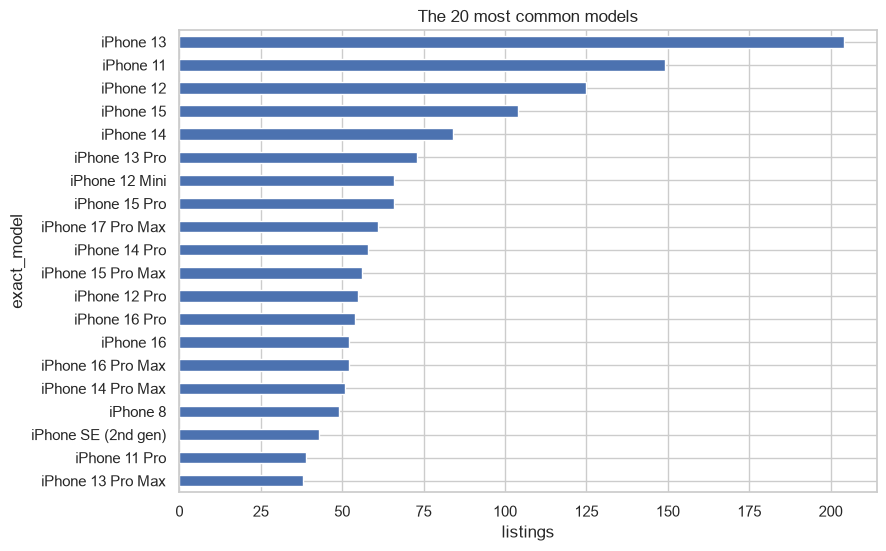

In [4]:
counts = df["exact_model"].value_counts()
print(f"{len(counts)} models; the 10 most common cover {counts.head(10).sum() / len(df):.0%} of listings; "
      f"{(counts < 5).sum()} models have fewer than 5 listings")

fig, ax = plt.subplots(figsize=(9, 6))
counts.head(20).sort_values().plot.barh(ax=ax)
ax.set(xlabel="listings", title="The 20 most common models")
plt.show()

**Takeaway:** 51 models, led by the iPhone 13 (204 listings), 11, 12, 15 and 14. The 10 most common models cover about half of the listings, and 4 models have fewer than 5 listings, so estimates for those will be rough.

## 4. Feature shortlist

**What:** the features the team shortlisted in the first-look session, with why each one should matter.
**Why:** to agree on inputs before modelling. The shortlist comes from the team's notes; region was marked "?".

| Feature | Why it should matter |
|---|---|
| `exact_model` | Newer models cost more (e.g. iPhone 15 vs iPhone 11) |
| `storage_gb` | More storage costs more within the same model |
| `condition` | Seller-picked condition: new, like new, good, fair, needs repair |
| `mentions_warranty` | Remaining warranty makes a phone worth more |
| `mentions_box` | Original box suggests a well-kept phone |
| `mentions_damage` | Cracks or broken parts lower the price. Negations ("ei halkeamia" = no cracks) don't count. |
| `seller_type` | Retailers may price differently from private sellers |
| `region` | **Open question ("?")**: prices may differ by region, but most listings are in Uusimaa |

`price_eur` is the target, not a feature. **`release_year` is not a model input**: it follows directly from `exact_model`, so it adds no new information (decided 24 Sep). It stays in the data for this analysis.

## 5. Seller types

**What:** how many listings come from private sellers vs retailers, and a yes/no private-seller flag.
**Why:** retailers may price differently. A number (True = 1) lets seller type appear in the correlation heatmap.

In [5]:
df["is_private"] = df["seller_type"].eq("private")
df.groupby("seller_type").agg(listings=("price_eur", "size"), median_price=("price_eur", "median"))

,listings,median_price
seller_type,,
private,1573,220.0
retailer,434,340.0


**Takeaway:** 1,573 private sellers and 434 retailers (22%). Retailers' median asking price is higher (340 € vs 220 €); step 6 shows how this relates to the other features.

## 6. Correlations

**What:** a heatmap of how the first-look columns move together: price, storage, release year, damage and box mentions, and the private-seller flag.
**Why:** a quick check of which features go with higher or lower prices.

**How:** Spearman correlation, which compares rankings. The first-look session used the default (Pearson), which is thrown off by the few very expensive phones; with rankings the relationships show more clearly. 1 = move together, −1 = move in opposite directions, 0 = unrelated.

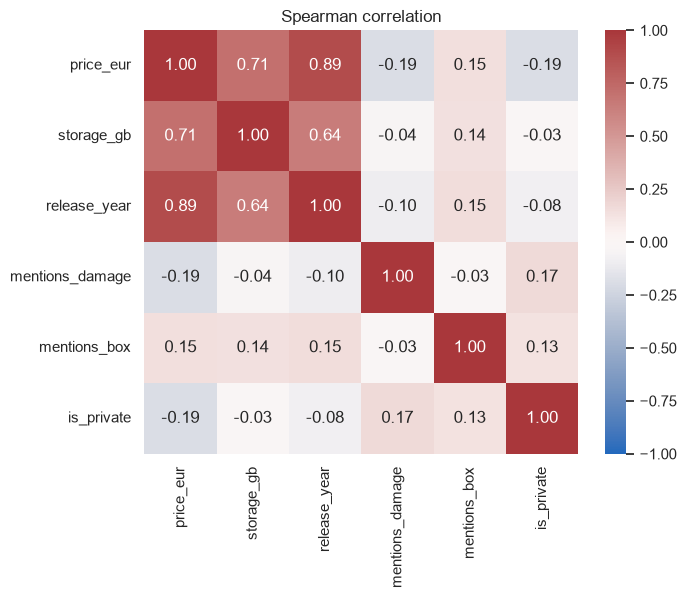

In [6]:
cols = ["price_eur", "storage_gb", "release_year", "mentions_damage", "mentions_box", "is_private"]
corr = df[cols].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation")
plt.show()

**Takeaway:** price goes most with **release year (0.89)** and **storage (0.71)**. Box mentions go with slightly higher prices (0.15); damage mentions (−0.19) and private sellers (−0.19) with lower ones. Release year and storage also move together (0.64): newer phones come with more storage, so their effects overlap.

## 7. Selected columns

**What:** a few listings with the columns the team looked at.
**Why:** to see the features as they look for real listings, not only as statistics.

In [7]:
df[["exact_model", "storage_gb", "condition", "mentions_damage", "mentions_box", "seller_type", "region", "price_eur"]].head(10)

,exact_model,storage_gb,condition,mentions_damage,mentions_box,seller_type,region,price_eur
0,iPhone 16 Pro,128.0,Kuin uusi,False,False,private,Uusimaa,700
1,iPhone 12,128.0,Vaatii korjausta,False,False,private,Uusimaa,40
2,iPhone 11,128.0,Hyvä,False,False,private,Pirkanmaa,95
3,iPhone 13,128.0,Hyvä,False,False,private,Uusimaa,199
4,iPhone 14 Pro Max,128.0,Kuin uusi,False,False,private,Varsinais-Suomi,350
5,iPhone 11,64.0,Hyvä,False,False,private,Satakunta,95
6,iPhone 14,128.0,Kuin uusi,False,False,private,Uusimaa,280
7,iPhone 16 Pro,256.0,Kuin uusi,False,True,private,Varsinais-Suomi,735
8,iPhone 11,64.0,Hyvä,False,False,private,Keski-Suomi,80
9,iPhone 17 Pro Max,256.0,Kuin uusi,False,False,private,Lappi,825


## 8. Summary

**What we have:** 2,007 cleaned iPhone listings, 51 models, and a shortlist of features that are almost all complete (battery % is the exception).

**What we saw**
- **Model and storage** go most with price; newer phones also tend to have more storage.
- **Retailers** ask more than private sellers (median 340 € vs 220 €).
- **Damage mentions** go with lower prices, **box mentions** with slightly higher ones.
- **4 models** have fewer than 5 listings, so estimates there will be rough.

**Decisions so far**
- `release_year` is not a model input: it follows from `exact_model` (24 Sep).
- `region` is still an open question from the shortlist.

**Next (for the team):** decide on region, then move on to modelling.